# Does industry composition change the wage-growth story?

Average hourly earnings can change because earnings change within industries
or because industries account for different shares of total paid hours.

This analysis asks whether changes in industry composition materially alter
the interpretation of recent private-sector earnings growth.

The workflow uses a dated BLS data snapshot, validates the analytical panel,
reconciles the reconstructed aggregate with published earnings, and produces
reproducible tables and charts.

The results describe broad industry averages—not wage changes for the same
individual workers.

In [10]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "wage_analysis.py").is_file():
    raise FileNotFoundError(
        "Run Jupyter from the repository root containing wage_analysis.py."
    )

sys.path.insert(0, str(PROJECT_ROOT))

from wage_analysis import (
    SERIES_SPEC,
    load_snapshot,
    audit_coverage,
    candidate_common_window,
    validate_selected_window,
    build_analysis_panel,
    calculate_paid_hours_weights,
    reconcile_headline_earnings,
)

from wage_decomposition import (
    build_decomposition_series,
    build_fixed_composition_series,
    rank_decomposition_contributions,
)

In [2]:
SNAPSHOT_PATH = (
    PROJECT_ROOT
    / "data"
    / "snapshots"
    / "snapshot_20261017T201430156177Z.json"
)

ANALYSIS_START = pd.Timestamp("2019-01-01")
ANALYSIS_END = pd.Timestamp("2026-09-01")

COMPARISON_BASE = pd.Timestamp("2025-09-01")
COMPARISON_END = ANALYSIS_END

FIXED_REFERENCE_DATE = COMPARISON_BASE

In [3]:
observations, metadata = load_snapshot(SNAPSHOT_PATH)
observations["date"] = pd.to_datetime(observations["date"])

coverage = audit_coverage(
    observations,
    SERIES_SPEC,
    start_date=observations["date"].min(),
    end_date=observations["date"].max(),
)

validate_selected_window(
    coverage,
    start_date=ANALYSIS_START,
    end_date=ANALYSIS_END,
)

component_panel = build_analysis_panel(
    observations,
    SERIES_SPEC,
    start_date=ANALYSIS_START,
    end_date=ANALYSIS_END,
)

benchmark_spec = [
    record for record in SERIES_SPEC
    if record.get("role") == "benchmark"
]

benchmark_lookup = {
    record["series_id"]: record
    for record in benchmark_spec
}

benchmark = observations.loc[
    observations["series_id"].isin(benchmark_lookup)
    & observations["date"].between(ANALYSIS_START, ANALYSIS_END)
].copy()

benchmark["metric"] = benchmark["series_id"].map(
    lambda sid: benchmark_lookup[sid]["metric"]
)
benchmark["industry_code"] = benchmark["series_id"].map(
    lambda sid: benchmark_lookup[sid]["industry_code"]
)
benchmark["industry_name"] = benchmark["series_id"].map(
    lambda sid: benchmark_lookup[sid]["industry_name"]
)
benchmark["role"] = "benchmark"

benchmark = benchmark.sort_values(
    ["date", "metric"]
).reset_index(drop=True)

benchmark_for_reconciliation = (
    benchmark.loc[
        benchmark["metric"].isin(
            ["average_hourly_earnings", "employment"]
        ),
        ["date", "metric", "value"],
    ]
    .assign(
        output_column=lambda df: df["metric"].map({
            "average_hourly_earnings": "published_total_private_ahe",
            "employment": "published_total_private_employment",
        })
    )
    .pivot(
        index="date",
        columns="output_column",
        values="value",
    )
    .reset_index()
)

benchmark_for_reconciliation.columns.name = None
benchmark_for_reconciliation["date"] = pd.to_datetime(
    benchmark_for_reconciliation["date"]
).dt.normalize()

required = {
    "date",
    "published_total_private_ahe",
    "published_total_private_employment",
}

missing = required - set(benchmark_for_reconciliation.columns)
if missing:
    raise ValueError(f"Benchmark is missing columns: {sorted(missing)}")

value_columns = [
    "published_total_private_ahe",
    "published_total_private_employment",
]

if benchmark_for_reconciliation[value_columns].isna().any().any():
    raise ValueError("Benchmark contains missing required values")

benchmark_for_reconciliation = benchmark_for_reconciliation.sort_values(
    "date"
).reset_index(drop=True)

weights = calculate_paid_hours_weights(component_panel)

weight_check = (
    weights.groupby("date", as_index=False)["weight"]
    .sum()
    .rename(columns={"weight": "weight_sum"})
)

reconciliation = reconcile_headline_earnings(
    component_panel,
    weights,
    benchmark_for_reconciliation,
)


In [5]:
# Cell 5 — Compute results and prepare chart data

import wage_decomposition as wd
import wage_interpretation as wi
import wage_presentation as wp

# Keep the annual comparison and fixed-reference analysis aligned.
if COMPARISON_END != COMPARISON_BASE + pd.DateOffset(months=12):
    raise ValueError("The headline comparison must span exactly 12 months.")

if FIXED_REFERENCE_DATE != COMPARISON_BASE:
    raise ValueError(
        "For this report, FIXED_REFERENCE_DATE must equal COMPARISON_BASE."
    )

# Adapt the Stage 2 column name for the decomposition functions.
stage3_panel = component_panel.rename(
    columns={"average_hourly_earnings": "ahe"}
)

# 1. Monthly and annual decompositions.
monthly_contributions, monthly_summary = wd.build_decomposition_series(
    stage3_panel,
    weights,
    benchmark_for_reconciliation,
    lag=1,
)

annual_contributions, annual_summary = wd.build_decomposition_series(
    stage3_panel,
    weights,
    benchmark_for_reconciliation,
    lag=12,
)

# 2. Earnings series with paid-hours weights held at the reference month.
fixed_composition = wd.build_fixed_composition_series(
    stage3_panel,
    weights,
    benchmark_for_reconciliation,
    reference_date=FIXED_REFERENCE_DATE,
)

# 3. Attach industry names before building interpretation tables and charts.
if "industry_name" not in annual_contributions.columns:
    industry_names = component_panel[
        ["industry_code", "industry_name"]
    ].drop_duplicates()

    annual_contributions = annual_contributions.merge(
        industry_names,
        on="industry_code",
        how="left",
        validate="many_to_one",
    )

# 4. Summarize the selected annual comparison.
interpretation = wi.build_interpretation_summary(
    annual_summary,
    fixed_composition,
    end_date=COMPARISON_END,
)

materiality = wi.summarize_composition_materiality(
    interpretation,
    annual_contributions,
    end_date=COMPARISON_END,
)

contributors = wi.build_composition_contributor_tables(
    annual_contributions,
    base_date=COMPARISON_BASE,
    end_date=COMPARISON_END,
    top_n=5,
)

# 5. Prepare chart data from the same analytical results.
headline_data = wp.build_headline_comparison_chart_data(
    annual_summary,
    fixed_composition,
    base_date=COMPARISON_BASE,
    end_date=COMPARISON_END,
)

contribution_data = wp.build_composition_contribution_chart_data(
    annual_contributions,
    base_date=COMPARISON_BASE,
    end_date=COMPARISON_END,
)

In [8]:
s = interpretation.iloc[0]

display(Markdown(f"""
## Main result

**Comparison:** {s["base_date"]:%B %Y} to {s["end_date"]:%B %Y}

Reconstructed nominal average hourly earnings changed by
**{s["reconstructed_change"]:+.3f} dollars per hour**, comprising:

- **Within-industry earnings:** {s["within_total"]:+.3f} dollars per hour.
- **Industry composition:** {s["composition_total"]:+.3f} dollars per hour.

The published total-private measure changed by
**{s["published_change"]:+.3f} dollars per hour**.

Fixed-composition weights are taken from
**{s["reference_date"]:%B %Y}**.
"""))


## Main result

**Comparison:** September 2025 to September 2026

Reconstructed nominal average hourly earnings changed by
**+1.110 dollars per hour**, comprising:

- **Within-industry earnings:** +1.154 dollars per hour.
- **Industry composition:** -0.044 dollars per hour.

The published total-private measure changed by
**+1.110 dollars per hour**.

Fixed-composition weights are taken from
**September 2025**.


Take Away: Industry composition modestly restrained aggregate earnings growth over this interval.  Most of the increase reflected higher average earnings within broad industries

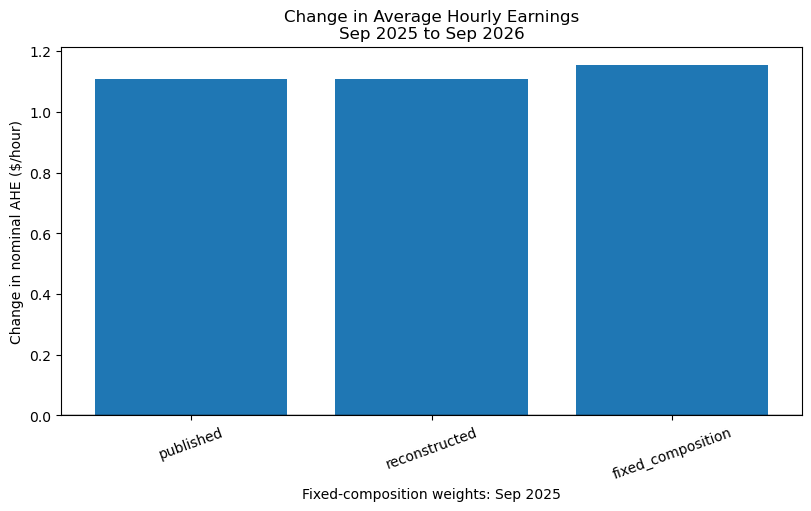

In [12]:
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)

wp.plot_headline_comparison_chart(headline_data, ax=ax)

ax.set_title(
    "Change in Average Hourly Earnings\n"
    f"{COMPARISON_BASE:%b %Y} to {COMPARISON_END:%b %Y}"
)
ax.set_ylabel("Change in nominal AHE ($/hour)")
ax.set_xlabel(f"Fixed-composition weights: {COMPARISON_BASE:%b %Y}")

plt.show()

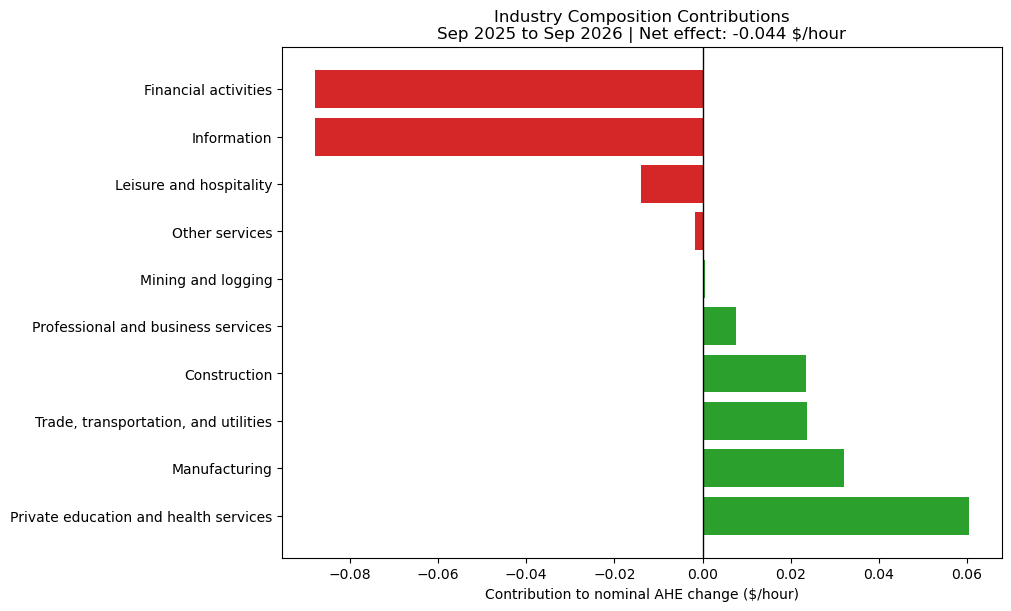

In [13]:
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

wp.plot_composition_contribution_chart(contribution_data, ax=ax)

net_effect = contribution_data["composition_contribution"].sum()

ax.set_title(
    "Industry Composition Contributions\n"
    f"{COMPARISON_BASE:%b %Y} to {COMPARISON_END:%b %Y}"
    f" | Net effect: {net_effect:+.3f} $/hour"
)
ax.set_xlabel("Contribution to nominal AHE change ($/hour)")

plt.show()

In [14]:
# Cell 12 — Run summary and validation

# Confirm coverage for the explicitly selected analysis window.
validate_selected_window(
    coverage,
    start_date=ANALYSIS_START,
    end_date=ANALYSIS_END,
)

run_summary = pd.Series(
    {
        "Snapshot": SNAPSHOT_PATH.name,
        "Retrieved (UTC)": metadata.get("retrieval_end_utc", "Not recorded"),
        "Analysis window": (
            f"{ANALYSIS_START:%b %Y} to {ANALYSIS_END:%b %Y}"
        ),
        "Headline comparison": (
            f"{COMPARISON_BASE:%b %Y} to {COMPARISON_END:%b %Y}"
        ),
        "Fixed-weight reference": f"{FIXED_REFERENCE_DATE:%b %Y}",
        "Selected-window coverage": "Validated",
        "Required series": len(coverage),
        "Component industries": component_panel["industry_code"].nunique(),
        "Months": component_panel["date"].nunique(),
        "Industry-month rows": len(component_panel),
    },
    name="Value",
).to_frame()

display(Markdown("## Data and validation"))
display(run_summary)

# Recompute arithmetic balances from the outputs.
weight_error = (
    weights.groupby("date")["weight"].sum(min_count=1) - 1
)

monthly_error = (
    monthly_summary["reconstructed_change"]
    - monthly_summary["within_total"]
    - monthly_summary["composition_total"]
)

annual_error = (
    annual_summary["reconstructed_change"]
    - annual_summary["within_total"]
    - annual_summary["composition_total"]
)

# These are numerical tolerances, not economic materiality thresholds.
check_inputs = [
    ("Weights sum to one", weight_error, "Share", 1e-10),
    ("Monthly decomposition balances", monthly_error, "USD/hour", 1e-10),
    ("Annual decomposition balances", annual_error, "USD/hour", 1e-10),
]

checks = pd.DataFrame(
    [
        {
            "Check": label,
            "Maximum absolute error": errors.abs().max(skipna=False),
            "Unit": unit,
            "Tolerance": tolerance,
        }
        for label, errors, unit, tolerance in check_inputs
    ]
).set_index("Check")

checks["Status"] = (
    checks["Maximum absolute error"]
    .le(checks["Tolerance"])
    .map({True: "PASS", False: "CHECK"})
)

display(Markdown("### Arithmetic checks across the analysis window"))
display(
    checks.style.format(
        {
            "Maximum absolute error": "{:.2e}",
            "Tolerance": "{:.0e}",
        }
    )
)

# Benchmark differences are separate from decomposition arithmetic.
benchmark_gaps = pd.DataFrame(
    {
        "Maximum absolute gap": reconciliation[
            ["earnings_residual", "employment_residual"]
        ].abs().max(skipna=False),
        "Unit": ["USD/hour", "Thousand employees"],
    }
).rename(
    index={
        "earnings_residual": "Published vs reconstructed AHE",
        "employment_residual": "Published vs component employment",
    }
)

display(Markdown("### Reconciliation with published totals"))
display(
    benchmark_gaps.style.format(
        {"Maximum absolute gap": "{:.6f}"}
    )
)

display(Markdown(
    "Arithmetic errors should be close to zero within numerical precision. "
    "Benchmark gaps measure agreement with the published totals and should "
    "be assessed separately. These checks establish accounting consistency; "
    "they do not establish economic causality or replace the test suite."
))

if checks["Status"].ne("PASS").any():
    raise ValueError("An arithmetic check failed; review the table above.")

## Data and validation

,Value
Snapshot,snapshot_20261017T201430156177Z.json
Retrieved (UTC),2026-10-17T20:14:30.156094Z
Analysis window,Jan 2019 to Sep 2026
Headline comparison,Sep 2025 to Sep 2026
Fixed-weight reference,Sep 2025
Selected-window coverage,Validated
Required series,33
Component industries,10
Months,93
Industry-month rows,930


### Arithmetic checks across the analysis window

,Maximum absolute error,Unit,Tolerance,Status
Check,,,,
Weights sum to one,2.22e-16,Share,1e-10,PASS
Monthly decomposition balances,1.16e-14,USD/hour,1e-10,PASS
Annual decomposition balances,9.98e-15,USD/hour,1e-10,PASS


### Reconciliation with published totals

,Maximum absolute gap,Unit
Published vs reconstructed AHE,0.006248,USD/hour
Published vs component employment,0.000000,Thousand employees


Arithmetic errors should be close to zero within numerical precision. Benchmark gaps measure agreement with the published totals and should be assessed separately. These checks establish accounting consistency; they do not establish economic causality or replace the test suite.